# T36. Capas del mapa 3D: demanda, red preliminar de estaciones y flujos

**Objetivo.** Exportar los datos del mapa 3D de la web (`frontend/public/demo/`): un mapa base minimalista de Roma, la demanda por celda y hora, el saldo por zona, una red preliminar de estaciones con su cobertura, flujos, anclajes, stock y energía, y un día de viajes del piloto para reproducirlo.

**Valor para el proyecto.** El mapa sirve para explicar en la defensa por qué las estaciones van donde van y qué cuesta cada decisión. La red de este notebook es **preliminar**: sale de una heurística voraz de cobertura máxima sobre los candidatos de resolución 9, para que el mapa tenga desde ya estaciones calculadas con los datos. La sustituirá la red elegida en T25–T28 con el mismo formato (contrato de la sección 8 de `docs/PLAN.md`).

Viajes elegibles del periodo de ajuste (1–21/02). Las distancias se calculan en metros sobre una proyección equirectangular local centrada en Roma (error inferior al 0,1 % a estas distancias).

In [1]:
import gzip
import hashlib
import json
import time

import h3
import numpy as np
import pandas as pd
import requests
import shapely
from IPython.display import display
from scipy.spatial import cKDTree
from shapely.geometry import LineString, MultiLineString, Polygon
from shapely.ops import linemerge, polygonize, unary_union

from comun.config import RAIZ, cargar_config, carpeta_tablas, ruta
from comun.datos import cargar_viajes
from comun.figuras import guardar_figura, plt

TEMA = "movilidad"
TABLAS = carpeta_tablas(TEMA)
TABLAS_EDA = ruta("tablas") / "exploracion"
CFG = cargar_config()
DEMO = RAIZ / "frontend" / "public" / "demo"
OSM = ruta("externos") / "osm"

PARAMETROS = {
    # Recorte del mapa base (oeste, sur, este, norte): el área de servicio con margen.
    "caja_mapa": (12.40, 41.79, 12.58, 41.97),
    "res_candidatos": CFG["movilidad"]["resolucion_candidatos"],
    "res_mapas": CFG["movilidad"]["resolucion_mapas"],
    "radios_m": CFG["movilidad"]["radios_acceso_m"],
    "k_max": 400,
    # Red de referencia de cada radio: la menor k con este porcentaje de viajes con los dos extremos cubiertos.
    "cobertura_objetivo_pct": 80,
    # Red que el mapa abre por defecto (radio del plan con menos estaciones sin pasar a la sensibilidad de 400 m).
    "radio_por_defecto_m": 300,
    # Inicio de la jornada operativa: el rebalanceo nocturno repone el stock a esta hora (T12: de 2 a 5 h casi no hay viajes).
    "hora_reposicion": 4,
    "flujos_max": 250,
    "consumo_wh_km": CFG["patinete"]["consumo_wh_km"],
    "bateria_wh": CFG["patinete"]["bateria_wh"],
}
ZONA = CFG["datos"]["zona_horaria"]
LAT0, LON0 = 41.89, 12.48
KX, KY = 111_320 * np.cos(np.radians(LAT0)), 110_574  # metros por grado de longitud y latitud


def a_metros(lon, lat):
    return np.c_[(np.asarray(lon, float) - LON0) * KX, (np.asarray(lat, float) - LAT0) * KY]


def guardar_tabla(df, nombre):
    df.to_csv(TABLAS / f"{nombre}.csv", index=False, lineterminator="\n")


def _json(x):
    if isinstance(x, np.ndarray):
        return x.tolist()
    if isinstance(x, np.generic):
        return x.item()
    raise TypeError(type(x))


EXPORTADOS = {}


def escribir(relativa, datos):
    """Escribe frontend/public/demo/<relativa> en JSON compacto y lo apunta para el manifiesto."""
    destino = DEMO / relativa
    destino.parent.mkdir(parents=True, exist_ok=True)
    texto = json.dumps(datos, ensure_ascii=False, separators=(",", ":"), default=_json)
    destino.write_text(texto, encoding="utf-8", newline="\n")
    EXPORTADOS[relativa] = hashlib.sha256(texto.encode()).hexdigest()
    return len(texto)


viajes = cargar_viajes(periodo="ajuste")
DIAS = viajes["tsO"].dt.normalize().nunique()
print(f"{len(viajes)} viajes elegibles en el periodo de ajuste, {DIAS} días")

16756 viajes elegibles en el periodo de ajuste, 21 días


## 1. Mapa base de Roma

**Qué queremos ver.** Un mapa base propio y ligero: vías principales y secundarias, calles, el Tíber y el Aniene, parques, vías de tren y las murallas, recortados al área de servicio y simplificados.

**Por qué importa.** El mapa tiene que funcionar sin conexión durante la defensa y ser reconocible sin competir con los datos. Por eso no se usa un servidor de teselas: se guardan las respuestas de OpenStreetMap en `datos/externos/osm/` (licencia ODbL, con su `.meta.json`) y aquí solo se simplifican. Solo se descargan si faltan.

In [2]:
CAPAS_OSM = ["vias", "calles", "agua", "verde", "tren", "murallas"]
META_OSM = sorted(OSM.glob("osm_roma_*.meta.json"))[-1]
meta_osm = json.loads(META_OSM.read_text(encoding="utf-8"))


def descargar_osm(capa, intentos=6):
    """Repite la consulta guardada en el .meta.json. Solo se llama si falta el fichero."""
    consulta = meta_osm["capas"][capa]["consulta"]
    for i in range(intentos):
        r = requests.post(meta_osm["url"], data={"data": consulta}, timeout=300,
                          headers={"User-Agent": "pids-proyecto3-mapa"})
        if r.ok and r.content.lstrip().startswith(b"{"):
            return r.content
        time.sleep(10 * (i + 1))  # Overpass pide reintentos espaciados cuando está saturado
    raise RuntimeError(f"Overpass no respondió para {capa}")


def leer_osm(capa):
    fichero = OSM / meta_osm["capas"][capa]["fichero"]
    if not fichero.exists():
        fichero.write_bytes(gzip.compress(descargar_osm(capa), mtime=0))
    crudo = gzip.decompress(fichero.read_bytes())
    if hashlib.sha256(crudo).hexdigest() != meta_osm["capas"][capa]["sha256"]:
        print(f"Aviso: {fichero.name} no coincide con la huella del .meta.json (descarga nueva)")
    return json.loads(crudo)["elements"]


osm = {capa: leer_osm(capa) for capa in CAPAS_OSM}
print({capa: len(e) for capa, e in osm.items()})

{'vias': 9623, 'calles': 26426, 'agua': 23, 'verde': 2917, 'tren': 710, 'murallas': 136}


In [3]:
CAJA = PARAMETROS["caja_mapa"]
M_GRADO = 111_000  # para pasar la tolerancia de simplificación de metros a grados


def _cuantizar(coords):
    """Coordenadas en enteros de 1e-5 grados (≈1 m) relativos a la esquina suroeste de la caja."""
    q = np.round((np.asarray(coords) - [CAJA[0], CAJA[1]]) * 1e5).astype(int)
    q = q[np.r_[True, np.any(np.diff(q, axis=0) != 0, axis=1)]]
    return q


def lineas(elementos, filtro, tol_m):
    geoms = [LineString([(p["lon"], p["lat"]) for p in e["geometry"]]) for e in elementos
             if e["type"] == "way" and len(e.get("geometry", [])) > 1 and filtro(e.get("tags", {}))]
    unidas = shapely.clip_by_rect(linemerge(MultiLineString(geoms)), *CAJA).simplify(tol_m / M_GRADO)
    salida = []
    for g in getattr(unidas, "geoms", [unidas]):
        if g.is_empty or g.geom_type != "LineString":
            continue
        q = _cuantizar(g.coords)
        if len(q) > 1:
            salida.append(q.ravel().tolist())
    return salida


def poligonos(elementos, area_min_m2, tol_m):
    piezas = []
    for e in elementos:
        geo = e.get("geometry")
        if e["type"] == "way" and geo and len(geo) > 3 and geo[0] == geo[-1]:
            piezas.append(Polygon([(p["lon"], p["lat"]) for p in geo]))
        elif e["type"] == "relation":
            anillos = {rol: [LineString([(p["lon"], p["lat"]) for p in m["geometry"]])
                             for m in e.get("members", []) if m.get("role") == rol and m.get("geometry")]
                       for rol in ("outer", "inner")}
            exteriores = list(polygonize(linemerge(anillos["outer"]))) if anillos["outer"] else []
            if exteriores:
                g = unary_union(exteriores)
                if anillos["inner"]:
                    g = g.difference(unary_union(list(polygonize(linemerge(anillos["inner"])))))
                piezas.append(g)
    g = unary_union([shapely.make_valid(p) for p in piezas])
    g = shapely.clip_by_rect(g, *CAJA).simplify(tol_m / M_GRADO)
    salida = []
    for p in getattr(g, "geoms", [g]):
        if p.is_empty or p.geom_type != "Polygon" or p.area * KX * KY < area_min_m2:
            continue
        salida.append([_cuantizar(a.coords).ravel().tolist() for a in [p.exterior, *p.interiors]])
    return salida


tipo = lambda *clases: (lambda t: t.get("highway") in clases)
base = {
    "origen": [CAJA[0], CAJA[1]],
    "escala": 1e-5,
    "vias_rapidas": lineas(osm["vias"], tipo("motorway", "trunk"), 5),
    "principales": lineas(osm["vias"], tipo("primary"), 4),
    "secundarias": lineas(osm["vias"], tipo("secondary", "tertiary"), 3),
    "calles": lineas(osm["calles"], tipo("residential", "unclassified", "living_street", "pedestrian"), 3),
    "rios": lineas(osm["agua"], lambda t: t.get("waterway") == "river", 5),
    "agua": poligonos([e for e in osm["agua"] if e.get("tags", {}).get("natural") == "water"], 0, 3),
    "verde": poligonos(osm["verde"], 15_000, 5),
    "tren": lineas(osm["tren"], lambda t: True, 4),
    "murallas": lineas(osm["murallas"], lambda t: True, 3),
    "atribucion": meta_osm["atribucion"],
}
# Referencias para orientarse en el mapa. Coordenadas aproximadas; no entran en ningún cálculo.
ETIQUETAS = [
    ("Colosseo", "monumento", 41.8902, 12.4922), ("San Pietro", "monumento", 41.9022, 12.4539),
    ("Termini", "monumento", 41.9009, 12.5017), ("Pantheon", "monumento", 41.8986, 12.4769),
    ("Piazza del Popolo", "monumento", 41.9107, 12.4764), ("Piazza Venezia", "monumento", 41.8960, 12.4823),
    ("Circo Massimo", "monumento", 41.8861, 12.4851), ("San Giovanni", "monumento", 41.8859, 12.5057),
    ("Piramide", "monumento", 41.8765, 12.4808), ("San Paolo", "monumento", 41.8587, 12.4769),
    ("Villa Borghese", "parque", 41.9135, 12.4855), ("Villa Pamphili", "parque", 41.8862, 12.4475),
    ("Trastevere", "barrio", 41.8890, 12.4695), ("Testaccio", "barrio", 41.8768, 12.4755),
    ("Prati", "barrio", 41.9075, 12.4620), ("Monti", "barrio", 41.8955, 12.4925),
    ("San Lorenzo", "barrio", 41.8978, 12.5155), ("Pigneto", "barrio", 41.8885, 12.5300),
    ("Ostiense", "barrio", 41.8640, 12.4790), ("Garbatella", "barrio", 41.8620, 12.4880),
    ("Parioli", "barrio", 41.9250, 12.4950), ("Flaminio", "barrio", 41.9240, 12.4700),
    ("Nomentano", "barrio", 41.9140, 12.5180), ("Esquilino", "barrio", 41.8945, 12.5040),
]
base["etiquetas"] = [{"nombre": n, "tipo": t, "lon": lon, "lat": lat} for n, t, lat, lon in ETIQUETAS]
tamano = escribir("base/roma.json", base)
resumen_base = pd.DataFrame([{"capa": k, "elementos": len(v), "vertices": sum(len(p) // 2 for p in v)}
                             for k, v in base.items() if k in ("vias_rapidas", "principales", "secundarias", "calles",
                                                               "rios", "tren", "murallas")]
                            + [{"capa": k, "elementos": len(v), "vertices": sum(len(a) // 2 for p in v for a in p)}
                               for k, v in base.items() if k in ("agua", "verde")])
display(resumen_base)
print(f"base/roma.json: {tamano / 1e6:.2f} MB")

,capa,elementos,vertices
0,vias_rapidas,27,546
1,principales,281,2149
2,secundarias,3361,13511
3,calles,13794,60294
4,rios,3,358
5,tren,64,1670
6,murallas,61,1162
7,agua,1,1453
8,verde,215,5939


base/roma.json: 0.98 MB


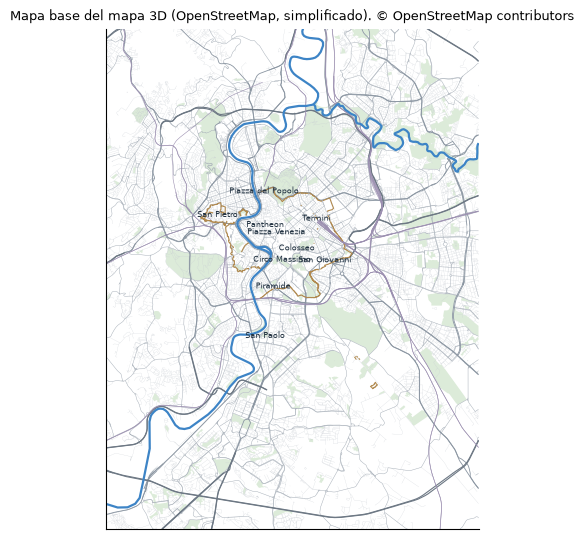

In [4]:
from matplotlib.collections import LineCollection, PolyCollection

dec = lambda a: np.asarray(a).reshape(-1, 2) * base["escala"] + base["origen"]
fig, eje = plt.subplots(figsize=(6.5, 6.5))
eje.add_collection(PolyCollection([dec(p[0]) for p in base["verde"]], facecolor="#dcebd9", edgecolor="none"))
for capa, ancho, color in [("calles", 0.15, "#c9ced4"), ("secundarias", 0.35, "#a9b1ba"), ("principales", 0.6, "#8a95a1"),
                           ("vias_rapidas", 0.8, "#6d7884"), ("tren", 0.4, "#9b8fb0"), ("murallas", 0.8, "#b0894f"),
                           ("rios", 1.6, "#3d84c6")]:
    eje.add_collection(LineCollection([dec(p) for p in base[capa]], linewidths=ancho, colors=color))
for e in base["etiquetas"]:
    if e["tipo"] == "monumento":
        eje.annotate(e["nombre"], (e["lon"], e["lat"]), fontsize=6, ha="center", color="#233342")
eje.set_xlim(CAJA[0], CAJA[2])
eje.set_ylim(CAJA[1], CAJA[3])
eje.set_aspect(1 / np.cos(np.radians(LAT0)))
eje.grid(False)
eje.set_xticks([])
eje.set_yticks([])
eje.set_title("Mapa base del mapa 3D (OpenStreetMap, simplificado). © OpenStreetMap contributors", fontsize=9)
guardar_figura(fig, TEMA, "T36_mapa_base")

**Conclusiones.**

- El mapa base pesa 0,98 MB sin comprimir: cabe en la web y carga sin conexión. Las coordenadas van en enteros de 1e-5 grados (≈ 1 m) respecto a la esquina suroeste.
- Se reconoce Roma con tres elementos: el Tíber, las murallas Aurelianas y la trama de calles. Los parques de menos de 1,5 ha y las calles de servicio no aportan y se quitan.

## 2. Demanda por celda y hora

**Qué queremos ver.** Orígenes y destinos por celda H3 de resolución 9 y hora del día, separados en laborable y fin de semana, como medias por día de ese tipo.

**Por qué importa.** Es la capa con la que el mapa enseña dónde y cuándo se mueve la demanda (T12 y T13) antes de hablar de estaciones. La resolución es la de los candidatos.

In [5]:
RES9 = PARAMETROS["res_candidatos"]


def celdas_de(lat, lon, res):
    return np.array([h3.latlng_to_cell(a, b, res) for a, b in zip(lat, lon)])


viajes["h9_o"] = celdas_de(viajes["latO"], viajes["lonO"], RES9)
viajes["h9_d"] = celdas_de(viajes["latD"], viajes["lonD"], RES9)
fin_de_semana = lambda ts: ts.dt.day_of_week >= 5
dias_tipo = viajes["tsO"].dt.normalize().drop_duplicates()
n_dias = {"laborable": int((dias_tipo.dt.day_of_week < 5).sum()), "fin_de_semana": int((dias_tipo.dt.day_of_week >= 5).sum())}

partes = []
for extremo, ts, h in (("o", "tsO", "h9_o"), ("d", "tsD", "h9_d")):
    t = pd.DataFrame({"h3": viajes[h], "hora": viajes[ts].dt.hour,
                      "tipo": np.where(fin_de_semana(viajes[ts]), "fin_de_semana", "laborable"), "extremo": extremo})
    partes.append(t)
eventos = pd.concat(partes, ignore_index=True)
cuenta = eventos.groupby(["h3", "tipo", "extremo", "hora"]).size().unstack("hora", fill_value=0).reindex(columns=range(24), fill_value=0)
total = eventos.groupby("h3").size().sort_values(ascending=False)
assert total.sum() == 2 * len(viajes)


def serie(h, tipo, extremo):
    clave = (h, tipo, extremo)
    return cuenta.loc[clave].to_numpy().tolist() if clave in cuenta.index else [0] * 24


celdas9 = [{"h3": h, "extremos": int(total[h]),
            "o": serie(h, "laborable", "o"), "d": serie(h, "laborable", "d"),
            "o_fds": serie(h, "fin_de_semana", "o"), "d_fds": serie(h, "fin_de_semana", "d")} for h in total.index]
tamano = escribir("demanda/celdas_res9.json", {"res": RES9, "dias": n_dias, "dias_total": DIAS,
                                               "unidad": "viajes en el periodo de ajuste por hora del día (dividir entre los días de cada tipo)",
                                               "celdas": celdas9})
print(f"{len(celdas9)} celdas, días {n_dias}; demanda/celdas_res9.json: {tamano / 1e3:.0f} kB")
print(f"Celda con más extremos: {total.index[0]} con {total.iloc[0] / DIAS:.1f} extremos/día")

600 celdas, días {'laborable': 15, 'fin_de_semana': 6}; demanda/celdas_res9.json: 158 kB
Celda con más extremos: 891e8050c3bffff con 24.2 extremos/día


**Conclusiones.**

- Son las mismas 600 celdas de resolución 9 con demanda que en T13; la suma de las series reproduce los 2 × 16 756 extremos del ajuste.
- La web divide por los días de cada tipo (15 laborables y 6 de fin de semana) para enseñar extremos por día y hora.

## 3. Saldo por zona (de T14)

**Qué queremos ver.** El saldo orígenes − destinos por celda de resolución 8, total y por franja, tal como lo calcula T14.

**Por qué importa.** Es la razón del rebalanceo nocturno y de que unas estaciones necesiten más stock y otras más anclajes. Se lee de las tablas de T14 para que el mapa enseñe las mismas cifras.

In [6]:
saldo = pd.read_csv(TABLAS_EDA / "T14_saldo_celdas.csv")
franjas = pd.read_csv(TABLAS_EDA / "T14_saldo_franjas.csv")
por_franja = franjas.pivot(index="h3", columns="franja", values="saldo_dia").fillna(0)
orden_franjas = list(CFG["exploracion"]["franjas_horarias"])
saldo_mapa = [{"h3": f.h3, "saldo_dia": round(f.saldo_dia, 3), "extremos": int(f.extremos), "tipo": f.tipo,
               "incluida": bool(f.incluida), "significativa": bool(f.signif_2sigma),
               "franjas": [round(float(por_franja.loc[f.h3, c]), 3) if f.h3 in por_franja.index and c in por_franja else 0
                           for c in orden_franjas]}
              for f in saldo.itertuples()]
escribir("demanda/saldo_res8.json", {"res": PARAMETROS["res_mapas"], "franjas": orden_franjas,
                                     "franjas_horas": [CFG["exploracion"]["franjas_horarias"][c] for c in orden_franjas],
                                     "unidad": "patinetes/día (orígenes − destinos); positivo: emisora",
                                     "celdas": saldo_mapa})
print(saldo["tipo"].value_counts().to_dict())

{'receptora': 45, 'emisora': 42, 'poco_uso': 21, 'equilibrada': 3}


**Conclusiones.**

- Se exportan las 111 celdas de T14 con el mismo criterio: solo las 90 con al menos 30 extremos se clasifican como emisoras o receptoras; el resto se marca como no incluida y el mapa la dibuja atenuada.

## 4. Red preliminar: barrido voraz de cobertura

**Qué queremos ver.** Para cada radio de acceso (200, 250, 300 y 400 m), cómo crece la demanda cubierta al añadir estaciones de una en una sobre los 600 centros de celda de resolución 9. En cada paso se añade la estación que cubre más extremos (orígenes o destinos) que todavía no estaban cubiertos.

**Por qué importa.** Es una aproximación rápida a la cobertura máxima (MCLP) de T27: la solución voraz garantiza al menos el 63 % del óptimo y en la práctica suele quedar muy cerca. Como las soluciones están anidadas (la red de k + 1 estaciones contiene la de k), el mapa puede enseñar con un deslizador qué se gana con cada estación más. La cobertura de un viaje sigue la definición del plan: **origen y destino dentro del radio** de alguna estación.

In [7]:
O = a_metros(viajes["lonO"], viajes["latO"])
D = a_metros(viajes["lonD"], viajes["latD"])
E = np.vstack([O, D])  # extremos: primero los orígenes y luego los destinos, en el orden de los viajes
N = len(viajes)
cand = pd.Series(np.r_[viajes["h9_o"], viajes["h9_d"]]).value_counts()
cand = cand.rename_axis("h3").rename("extremos").reset_index()
centros = np.array([h3.cell_to_latlng(c) for c in cand["h3"]])
cand["lat"], cand["lon"] = centros[:, 0], centros[:, 1]
C = a_metros(cand["lon"], cand["lat"])
arbol = cKDTree(E)


def barrido_voraz(radio, k_max):
    bolas = arbol.query_ball_point(C, r=radio)
    ganancia = np.array([len(b) for b in bolas], float)  # cota superior para la evaluación perezosa
    cubierto = np.zeros(len(E), bool)
    d_min = np.full(len(E), np.inf)
    libre = np.ones(len(C), bool)
    filas = []
    for k in range(1, k_max + 1):
        mejor, g_mejor = -1, -1
        for i in np.argsort(-np.where(libre, ganancia, -1), kind="stable"):
            if not libre[i] or ganancia[i] <= g_mejor:
                break
            ganancia[i] = (~cubierto[bolas[i]]).sum()
            if ganancia[i] > g_mejor:
                mejor, g_mejor = i, int(ganancia[i])
        libre[mejor] = False
        cubierto[bolas[mejor]] = True
        d_min = np.minimum(d_min, np.hypot(*(E - C[mejor]).T))
        ambos = cubierto[:N] & cubierto[N:]
        filas.append({"radio_m": radio, "k": k, "h3": cand.at[mejor, "h3"], "lat": round(cand.at[mejor, "lat"], 6),
                      "lon": round(cand.at[mejor, "lon"], 6), "ganancia_extremos": g_mejor,
                      "pct_extremos": 100 * cubierto.mean(), "pct_viajes": 100 * ambos.mean(),
                      "d_mediana_m": float(np.median(d_min)), "d_p90_m": float(np.quantile(d_min, 0.9))})
    return pd.DataFrame(filas)


barrido = pd.concat([barrido_voraz(r, PARAMETROS["k_max"]) for r in PARAMETROS["radios_m"]], ignore_index=True)
guardar_tabla(barrido.round({"pct_extremos": 3, "pct_viajes": 3, "d_mediana_m": 1, "d_p90_m": 1}), "T36_barrido_voraz")

obj = PARAMETROS["cobertura_objetivo_pct"]
k_ref = {r: int(b.loc[b["pct_viajes"] >= obj, "k"].min()) for r, b in barrido.groupby("radio_m")}
orden_mag = pd.read_csv(TABLAS_EDA / "T13_estaciones_orden_magnitud.csv")
display(orden_mag.head(8))
fila_k = lambda r, k: barrido[(barrido["radio_m"] == r) & (barrido["k"] == k)].iloc[0]
tabla_k = pd.DataFrame([{"radio_m": r, f"k_{obj}pct_viajes": k,
                         "ganancia_primera_extremos_dia": round(fila_k(r, 1)["ganancia_extremos"] / DIAS, 1),
                         "ganancia_ultima_extremos_dia": round(fila_k(r, k)["ganancia_extremos"] / DIAS, 2),
                         "pct_extremos": round(fila_k(r, k)["pct_extremos"], 1),
                         "d_mediana_m": round(fila_k(r, k)["d_mediana_m"]),
                         "d_p90_m": round(fila_k(r, k)["d_p90_m"])}
                        for r, k in k_ref.items()])
display(tabla_k)

,radio_m,cuota_pct,res,celdas,area_km2,area_por_estacion_km2,estaciones_orden_magnitud
0,200,50,9,94,9.90,0.1039,96
1,200,80,9,226,23.81,0.1039,230
2,200,90,9,312,32.86,0.1039,317
3,200,95,9,381,40.13,0.1039,387
4,250,50,9,94,9.90,0.1624,61
5,250,80,9,226,23.81,0.1624,147
6,250,90,9,312,32.86,0.1624,203
7,250,95,9,381,40.13,0.1624,248


,radio_m,k_80pct_viajes,ganancia_primera_extremos_dia,ganancia_ultima_extremos_dia,pct_extremos,d_mediana_m,d_p90_m
0,200,290,24.5,1.57,88.5,140,211
1,250,228,32.5,1.71,88.8,149,260
2,300,162,37.7,2.33,88.9,176,307
3,400,87,63.5,4.86,88.9,265,411


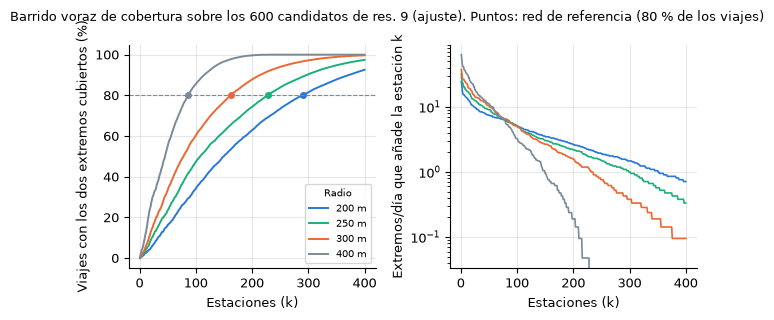

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(6.5, 3.2))
colores = dict(zip(PARAMETROS["radios_m"], ["#2a78d6", "#1baf7a", "#eb6834", "#7a8a99"]))
for r, b in barrido.groupby("radio_m"):
    ejes[0].plot(b["k"], b["pct_viajes"], color=colores[r], lw=1.4, label=f"{r} m")
    ejes[0].plot(k_ref[r], obj, "o", color=colores[r], ms=4)
    ejes[1].plot(b["k"], b["ganancia_extremos"] / DIAS, color=colores[r], lw=1.2)
ejes[0].axhline(obj, color="#7a8a99", lw=0.8, ls="--")
ejes[0].set_xlabel("Estaciones (k)")
ejes[0].set_ylabel("Viajes con los dos extremos cubiertos (%)")
ejes[0].legend(title="Radio", fontsize=7, title_fontsize=7)
ejes[1].set_xlabel("Estaciones (k)")
ejes[1].set_ylabel("Extremos/día que añade la estación k")
ejes[1].set_yscale("log")
fig.suptitle("Barrido voraz de cobertura sobre los 600 candidatos de res. 9 (ajuste). Puntos: red de referencia "
             f"({obj} % de los viajes)", fontsize=9)
fig.tight_layout()
guardar_figura(fig, TEMA, "T36_cobertura_voraz")

**Conclusiones.**

- Con el criterio de cubrir el 80 % de los viajes en los dos extremos salen **290 estaciones con 200 m, 228 con 250 m, 162 con 300 m y 87 con 400 m**. Las cuatro caen dentro del rango que T13 estimaba solo por área (230–387, 147–248, 102–172 y 58–97), lo que confirma ese orden de magnitud con una localización concreta.
- La curva tiene rendimientos decrecientes claros: la primera estación con 300 m cubre unos 38 extremos al día y la que cierra la red de referencia, 2,3. Es el argumento de la defensa para no perseguir el 100 %: las últimas estaciones apenas captan demanda.
- Pasar de 162 a 400 estaciones con 300 m solo baja la distancia mediana a la estación más cercana de 176 a 138 m, contando todos los extremos; el P90 baja de 307 a 200 m (tabla `T36_barrido_voraz.csv`). Lo que se compra con más estaciones es sobre todo cubrir la periferia.
- Es una red **preliminar**: la elección final (T25–T28) comparará esta heurística con LSCP, p-mediana y MCLP exactos sobre los mismos candidatos.

## 5. Redes de referencia: asignación, flujos, stock, anclajes y energía

**Qué queremos ver.** Para la red de referencia de cada radio: qué viajes atiende (los dos extremos a menos del radio de su estación más cercana), las salidas y llegadas de cada estación, los flujos entre estaciones, el stock inicial y los anclajes con rebalanceo nocturno, y la energía que llega a cada estación.

**Por qué importa.** Es lo que enseña la ficha de cada estación en el mapa: por qué está ahí, cuánto se usa, cuántos anclajes pide y cuánta energía hay que reponer. Las cifras de stock y anclajes son una **referencia de capacidad** (sección 4 del plan): asignación fija, sin rechazos y con el stock repuesto cada noche a las 4 h. La simulación con restricciones de T32 las sustituirá.

- **Stock inicial** de una estación: lo que necesita a las 4 h para no quedarse vacía en su peor jornada del ajuste. Es el máximo, entre jornadas, de lo que llega a bajar el inventario acumulado (llegadas − salidas, con las llegadas antes que las salidas a la misma hora).
- **Anclajes**: el máximo de patinetes anclados a la vez en cualquier jornada partiendo de ese stock.
- **Rebalanceo nocturno**: patinetes que hay que retirar de las estaciones con excedente al final de cada jornada para volver al stock inicial.
- **Energía**: 13,5 Wh/km por la distancia recorrida de cada viaje atendido, asignada a la estación de llegada (modelo de referencia de T16).

In [9]:
HORA0 = PARAMETROS["hora_reposicion"]
viajes["energia_wh"] = PARAMETROS["consumo_wh_km"] * viajes["dis_m"] / 1000
jornada_o = (viajes["tsO"] - pd.Timedelta(hours=HORA0)).dt.normalize()
jornada_d = (viajes["tsD"] - pd.Timedelta(hours=HORA0)).dt.normalize()


def red_de_referencia(radio):
    b = barrido[barrido["radio_m"] == radio].head(k_ref[radio]).reset_index(drop=True)
    pos = a_metros(b["lon"], b["lat"])
    dist, idx = cKDTree(pos).query(E)
    dist_o, dist_d, est_o, est_d = dist[:N], dist[N:], idx[:N], idx[N:]
    atendido = (dist_o <= radio) & (dist_d <= radio)
    v = viajes.loc[atendido]
    eo, ed = est_o[atendido], est_d[atendido]
    k = len(b)

    # Salidas y llegadas por estación, hora y tipo de día (recuentos del periodo).
    def perfil(est, ts):
        fds = (ts.dt.day_of_week >= 5).to_numpy()
        hora = ts.dt.hour.to_numpy()
        lab = np.zeros((k, 24), int)
        fin = np.zeros((k, 24), int)
        np.add.at(lab, (est[~fds], hora[~fds]), 1)
        np.add.at(fin, (est[fds], hora[fds]), 1)
        return lab, fin

    sal_lab, sal_fds = perfil(eo, v["tsO"])
    lle_lab, lle_fds = perfil(ed, v["tsD"])
    energia_hora = np.zeros((k, 24))
    np.add.at(energia_hora, (ed, v["tsD"].dt.hour.to_numpy()), v["energia_wh"].to_numpy())

    # Inventario por jornada: +1 en cada llegada y −1 en cada salida, llegadas primero a igual hora.
    ev = pd.DataFrame({"est": np.r_[ed, eo], "ts": pd.concat([v["tsD"], v["tsO"]], ignore_index=True),
                       "jornada": pd.concat([jornada_d[atendido], jornada_o[atendido]], ignore_index=True),
                       "delta": np.r_[np.ones(len(v), int), -np.ones(len(v), int)]})
    ev = ev.sort_values(["est", "jornada", "ts", "delta"], ascending=[True, True, True, False], kind="stable")
    ev["acum"] = ev.groupby(["est", "jornada"])["delta"].cumsum()
    por_jornada = ev.groupby(["est", "jornada"])["acum"].agg(["min", "max", "last"])
    stock = (-por_jornada["min"]).clip(lower=0).groupby("est").max().reindex(range(k), fill_value=0)
    pico = por_jornada["max"].clip(lower=0)
    ocupacion_max = (stock.reindex(pico.index.get_level_values("est")).to_numpy() + pico.to_numpy())
    anclajes = pd.Series(ocupacion_max, index=pico.index).groupby("est").max().reindex(range(k), fill_value=0)
    anclajes = np.maximum(anclajes, stock).clip(lower=1)
    retirar = por_jornada["last"].clip(lower=0).groupby("jornada").sum()

    est = b[["k", "h3", "lat", "lon", "ganancia_extremos"]].rename(columns={"k": "rango"})
    est.insert(0, "station_id", [f"E{i:03d}" for i in est["rango"]])
    est["extremos_en_radio"] = [int(((dist_o <= radio) & (est_o == i)).sum() + ((dist_d <= radio) & (est_d == i)).sum())
                                for i in range(k)]
    est["salidas"] = sal_lab.sum(1) + sal_fds.sum(1)
    est["llegadas"] = lle_lab.sum(1) + lle_fds.sum(1)
    est["salidas_dia"] = est["salidas"] / DIAS
    est["llegadas_dia"] = est["llegadas"] / DIAS
    est["saldo_dia"] = (est["salidas"] - est["llegadas"]) / DIAS
    est["stock_inicial"] = stock.to_numpy()
    est["anclajes"] = anclajes.to_numpy()
    est["energia_kwh_dia"] = energia_hora.sum(1) / 1000 / DIAS
    est["cargas_dia"] = energia_hora.sum(1) / PARAMETROS["bateria_wh"] / DIAS
    est["rotacion_dia"] = (est["salidas_dia"] / est["anclajes"])

    pares = pd.DataFrame({"o": eo, "d": ed}).value_counts().rename("viajes").reset_index()
    resumen = {
        "network_id": f"voraz_r{radio}", "radio_m": radio, "estaciones": k,
        "pct_viajes_atendidos": 100 * atendido.mean(),
        "pct_origenes_cubiertos": 100 * (dist_o <= radio).mean(), "pct_destinos_cubiertos": 100 * (dist_d <= radio).mean(),
        "d_origen_mediana_m": float(np.median(dist_o)), "d_destino_mediana_m": float(np.median(dist_d)),
        "d_origen_p90_m": float(np.quantile(dist_o, 0.9)), "d_destino_p90_m": float(np.quantile(dist_d, 0.9)),
        "d_atendidos_media_m": float(np.r_[dist_o[atendido], dist_d[atendido]].mean()),
        "viajes_atendidos_dia": atendido.sum() / DIAS,
        "flota": int(est["stock_inicial"].sum()), "anclajes": int(est["anclajes"].sum()),
        "anclajes_mediana": float(est["anclajes"].median()), "anclajes_max": int(est["anclajes"].max()),
        "rebalanceo_noche_media": float(retirar.mean()), "rebalanceo_noche_max": int(retirar.max()),
        "pct_viajes_misma_estacion": 100 * (eo == ed).mean(),
        "kwh_dia_total": est["energia_kwh_dia"].sum(), "kwh_dia_estacion_max": est["energia_kwh_dia"].max(),
        "kwh_dia_estacion_mediana": est["energia_kwh_dia"].median(),
        "viajes_por_patinete_dia": atendido.sum() / DIAS / est["stock_inicial"].sum(),
    }
    # Conciliación: cada viaje atendido sale de una estación y llega a una; la energía cuadra con la de los viajes.
    assert est["salidas"].sum() == est["llegadas"].sum() == atendido.sum() == pares["viajes"].sum()
    assert np.isclose(energia_hora.sum(), v["energia_wh"].sum())
    assert (est["anclajes"] >= est["stock_inicial"]).all()
    return {"estaciones": est, "pares": pares, "resumen": resumen, "atendido": atendido,
            "est_o": est_o, "est_d": est_d,
            "perfiles": {"salidas": sal_lab, "llegadas": lle_lab, "salidas_fds": sal_fds, "llegadas_fds": lle_fds,
                         "energia_wh": energia_hora}}


redes = {r: red_de_referencia(r) for r in PARAMETROS["radios_m"]}
resumen_redes = pd.DataFrame([red["resumen"] for red in redes.values()])
guardar_tabla(resumen_redes.round(3), "T36_redes_referencia")
for r, red in redes.items():
    guardar_tabla(red["estaciones"].round(4), f"T36_estaciones_voraz_r{r}")
display(resumen_redes.set_index("radio_m").T.round(2))

radio_m,200,250,300,400
network_id,voraz_r200,voraz_r250,voraz_r300,voraz_r400
estaciones,290,228,162,87
pct_viajes_atendidos,80.078778,80.108618,80.126522,80.317498
pct_origenes_cubiertos,90.111005,90.475054,90.504894,90.481022
pct_destinos_cubiertos,86.840535,87.132967,87.222487,87.234423
d_origen_mediana_m,138.14645,145.772941,171.984323,261.62554
d_destino_mediana_m,142.210305,151.135188,178.772097,268.798048
d_origen_p90_m,199.471996,246.255359,297.468692,395.097906
d_destino_p90_m,235.028653,275.561531,317.430924,428.230845
d_atendidos_media_m,124.3239,134.796628,162.819478,239.070204


In [10]:
def exportar_red(radio):
    red = redes[radio]
    est, nid = red["estaciones"], red["resumen"]["network_id"]
    redondeo = {"salidas_dia": 2, "llegadas_dia": 2, "saldo_dia": 2, "energia_kwh_dia": 4, "cargas_dia": 3, "rotacion_dia": 3}
    rasgos = []
    for f in est.round(redondeo).to_dict(orient="records"):
        lon, lat = f.pop("lon"), f.pop("lat")
        rasgos.append({"type": "Feature", "geometry": {"type": "Point", "coordinates": [round(lon, 6), round(lat, 6)]},
                       "properties": f})
    escribir(f"networks/{nid}/stations.geojson", {"type": "FeatureCollection", "features": rasgos})
    p = red["perfiles"]
    escribir(f"networks/{nid}/perfiles.json", {
        "unidad": "recuentos del periodo de ajuste por hora (dividir entre los días de cada tipo); energía en Wh del periodo",
        "dias": n_dias, "dias_total": DIAS,
        "estaciones": [{"station_id": s, "salidas": p["salidas"][i], "llegadas": p["llegadas"][i],
                        "salidas_fds": p["salidas_fds"][i], "llegadas_fds": p["llegadas_fds"][i],
                        "energia_wh": np.round(p["energia_wh"][i], 1)} for i, s in enumerate(est["station_id"])]})
    pares = red["pares"]
    entre = pares[pares["o"] != pares["d"]].head(PARAMETROS["flujos_max"])
    escribir(f"networks/{nid}/flujos.json", {
        "unidad": "viajes en el periodo de ajuste", "dias": DIAS,
        "viajes_atendidos": int(pares["viajes"].sum()),
        "viajes_misma_estacion": int(pares.loc[pares["o"] == pares["d"], "viajes"].sum()),
        "pares_con_viajes": len(pares),
        "pares": [[est.at[o, "station_id"], est.at[d, "station_id"], int(n)] for o, d, n in entre.itertuples(index=False)]})


for r in PARAMETROS["radios_m"]:
    exportar_red(r)
escribir("networks/barrido.json", {
    "criterio": f"menor k con el {obj} % de los viajes con los dos extremos cubiertos",
    "dias": DIAS, "viajes": N,
    "radios": {str(r): {"k_referencia": k_ref[r], "network_id": f"voraz_r{r}",
                        "h3": b["h3"].tolist(), "lon": b["lon"].round(6).tolist(), "lat": b["lat"].round(6).tolist(),
                        "ganancia_extremos": b["ganancia_extremos"].tolist(), "pct_viajes": b["pct_viajes"].round(2).tolist(),
                        "pct_extremos": b["pct_extremos"].round(2).tolist(), "d_mediana_m": b["d_mediana_m"].round().astype(int).tolist(),
                        "d_p90_m": b["d_p90_m"].round().astype(int).tolist()}
               for r, b in barrido.groupby("radio_m")}})
print(sorted(k for k in EXPORTADOS if k.startswith("networks")))

['networks/barrido.json', 'networks/voraz_r200/flujos.json', 'networks/voraz_r200/perfiles.json', 'networks/voraz_r200/stations.geojson', 'networks/voraz_r250/flujos.json', 'networks/voraz_r250/perfiles.json', 'networks/voraz_r250/stations.geojson', 'networks/voraz_r300/flujos.json', 'networks/voraz_r300/perfiles.json', 'networks/voraz_r300/stations.geojson', 'networks/voraz_r400/flujos.json', 'networks/voraz_r400/perfiles.json', 'networks/voraz_r400/stations.geojson']


**Conclusiones.**

- Con la red de referencia de 300 m (162 estaciones) se atiende el 80,1 % de los viajes del ajuste. Con el stock repuesto cada noche harían falta unos **697 patinetes y 1 448 anclajes**, frente a los 2 331 patinetes distintos del piloto y los 487,8 que se usaban de media cada día (T12). La flota sale de sumar el peor día de cada estación, así que es conservadora.
- El rebalanceo nocturno de esa red mueve de media 119 patinetes por noche (máximo 159), entre las dos cotas de T14 (101,5 en resolución 8 y 221,6 en la 9): cada estación recoge menos área que una celda de resolución 8, así que se compensan menos saldos dentro de ella.
- El 12,3 % de los viajes atendidos sale y llega a la misma estación (T15 anticipaba viajes circulares y T20 un 21,4 % intrazonal en resolución 8).
- Las 162 estaciones reciben 17,6 kWh/día en total (el 79 % de los 22,1 de T16, porque se atienden el 80 % de los viajes). La que más recibe, 0,32 kWh/día, y la mediana, 0,09 kWh/día: menos de una batería de patinete (0,576 kWh) al día por estación. Es la escala con la que se dimensionará la estación fotovoltaica (T50–T55).

## 6. Un día del piloto para reproducir

**Qué queremos ver.** Los viajes de una jornada laborable típica del ajuste (la de recuento más cercano a la mediana de los laborables), con su hora de salida y llegada y si los atiende cada red de referencia, y la ocupación de cada estación cada 15 minutos en esa jornada.

**Por qué importa.** El mapa abre reproduciendo este día. Como el CSV no trae trayectorias, cada viaje se dibuja como una línea recta entre origen y destino durante su duración real: **la geometría es ilustrativa**, las horas y los extremos son los observados.

In [11]:
por_dia = viajes.groupby(jornada_o).size()
laborables = por_dia[por_dia.index.day_of_week < 5]
dia = (laborables - laborables.median()).abs().sort_values(kind="stable").index[0]
inicio = dia + pd.Timedelta(hours=HORA0)
en_dia = (jornada_o == dia).to_numpy()
seg = lambda ts: (ts - inicio).dt.total_seconds().round().astype(int).to_numpy()
r0 = PARAMETROS["radio_por_defecto_m"]
dv = viajes.loc[en_dia]
# Si lo atiende cada red de referencia, como máscara de bits en el orden de PARAMETROS["radios_m"].
mascara = sum(redes[r]["atendido"][en_dia].astype(int) << i for i, r in enumerate(PARAMETROS["radios_m"]))
filas_dia = [[round(a, 5), round(b, 5), round(c, 5), round(d, 5), int(s), int(l), int(m)] for a, b, c, d, s, l, m in
             zip(dv["lonO"], dv["latO"], dv["lonD"], dv["latD"], seg(dv["tsO"]), seg(dv["tsD"]), mascara)]

# Ocupación cada 15 min de cada estación de cada red de referencia en esa jornada.
pasos = np.arange(0, 24 * 3600 + 1, 900)
ocupacion = {}
for r, red in redes.items():
    # Igual que en la referencia de capacidad: cada llegada y cada salida cuenta en su propia jornada.
    lle = red["atendido"] & (jornada_d == dia).to_numpy()
    sal = red["atendido"] & en_dia
    occ = np.tile(red["estaciones"]["stock_inicial"].to_numpy(), (len(pasos), 1)).astype(int)
    for est, ts, signo in ((red["est_d"][lle], viajes.loc[lle, "tsD"], 1), (red["est_o"][sal], viajes.loc[sal, "tsO"], -1)):
        t = seg(ts)
        for j, tt in enumerate(pasos):
            hasta = t <= tt
            np.add.at(occ[j], est[hasta], signo)
    assert (occ >= 0).all() and (occ <= red["estaciones"]["anclajes"].to_numpy()).all()
    ocupacion[red["resumen"]["network_id"]] = occ.T

escribir(f"dia/{dia:%Y-%m-%d}.json", {
    "fecha": f"{dia:%Y-%m-%d}", "inicio": inicio.isoformat(), "zona_horaria": ZONA,
    "viajes_campos": ["lonO", "latO", "lonD", "latD", "s_salida", "s_llegada", "atendido"],
    "atendido_bits": PARAMETROS["radios_m"],
    "viajes": filas_dia,
    "paso_s": 900, "ocupacion": {nid: occ for nid, occ in ocupacion.items()},
    "nota": "Segundos desde el inicio de la jornada operativa. Línea recta entre extremos: geometría ilustrativa."})
print(f"Jornada {dia:%d/%m/%Y} (día {dia.day_of_week + 1} de la semana) desde las {HORA0} h: {en_dia.sum()} viajes "
      f"(mediana de laborables {laborables.median():.0f}), {redes[r0]['atendido'][en_dia].mean():.1%} atendidos con {r0} m")

Jornada 04/02/2021 (día 4 de la semana) desde las 4 h: 799 viajes (mediana de laborables 799), 79.1% atendidos con 300 m


**Conclusiones.**

- La jornada elegida es la del jueves 04/02/2021 con 799 viajes. La ocupación de cada estación nunca baja de cero ni pasa de sus anclajes: lo garantiza la referencia de capacidad del apartado 5.

## 7. Manifiesto

**Qué queremos ver.** El índice de todo lo exportado (`manifest.json`) con el identificador de la ejecución, las redes, la jornada y las cifras de la fase 0 que cita el relato del mapa, leídas de sus tablas.

**Por qué importa.** La web no escribe ninguna cifra a mano: las saca de aquí, así que el mapa, la memoria y las tablas dicen lo mismo. El `run_id` es la huella de todos los ficheros exportados; cambia si cambia cualquier dato.

In [12]:
leer_resumen = lambda nombre: pd.read_csv(TABLAS_EDA / f"{nombre}.csv").set_index("indicador")["valor"]
t12, t14, t15r, t16 = (leer_resumen(n) for n in ("T12_resumen", "T14_resumen", "T15_resumen", "T16_resumen"))
t13 = pd.read_csv(TABLAS_EDA / "T13_concentracion.csv").set_index("res")
t15 = pd.read_csv(TABLAS_EDA / "T15_radios_acceso.csv").set_index("radio_m")
embudo = pd.read_csv(TABLAS_EDA / "T10_embudo.csv")
t20 = pd.read_csv(ruta("tablas") / "movilidad" / "T20_resumen.csv").set_index("indicador")["valor"]
num = lambda x: int(float(x)) if float(x).is_integer() else float(x)
patinetes_csv = cargar_viajes(solo_elegibles=False)["idS"].nunique()

cifras = {
    "viajes_csv": int(embudo["quedan"].iat[0]), "viajes_elegibles": num(t12["viajes_elegibles"]),
    "patinetes_mes": int(patinetes_csv), "patinetes_elegibles": num(t12["patinetes_mes"]),
    "viajes_ajuste": N, "dias_ajuste": DIAS,
    "viajes_dia_ajuste": num(t12["viajes_dia_media_ajuste"]),
    "viajes_dia_reservada": num(t12["viajes_dia_media_reservada"]),
    "viajes_dia_laborable": num(t12["viajes_dia_laborable_ajuste"]),
    "viajes_dia_fin_de_semana": num(t12["viajes_dia_fin_de_semana_ajuste"]),
    "diferencia_perfiles_pc": num(t12["diferencia_perfiles_laborable_finde_pc"]),
    "hora_punta_laborable": num(t12["hora_punta_laborable"]), "hora_punta_fin_de_semana": num(t12["hora_punta_fin_de_semana"]),
    "simultaneos_max": num(t12["simultaneos_max_ajuste"]),
    "patinetes_activos_dia": num(t12["patinetes_activos_dia_media_ajuste"]),
    "celdas9_con_demanda": int(t13.at[9, "celdas_con_demanda"]),
    "celdas9_50pct": int(t13.at[9, "celdas_50pct"]), "celdas9_80pct": int(t13.at[9, "celdas_80pct"]),
    "area9_50pct_km2": float(t13.at[9, "area_50pct_km2"]),
    "pct_extremos_top20pct_celdas9": float(t13.at[9, "pct_extremos_top20pct_celdas"]),
    "celdas8_emisoras": num(t14["celdas_emisoras"]), "celdas8_receptoras": num(t14["celdas_receptoras"]),
    "rebalanceo_res8_dia": num(t14["cota_rebalanceo_res8_media_patinetes_dia"]),
    "rebalanceo_res9_dia": num(t14["cota_rebalanceo_res9_media_patinetes_dia"]),
    "rebalanceo_res8_dia_max": num(t14["cota_rebalanceo_res8_max_patinetes_dia"]),
    "rebalanceo_base_dia": CFG["movilidad"]["rebalanceo_base_patinetes_dia"],
    "operador_pct_saldo_compensado": num(t14["operador_pct_saldo_compensado"]),
    "rodeo_mediana": num(t15r["rodeo_mediana"]), "velocidad_pie_ms": num(t15r["velocidad_pie_ms"]),
    "pct_viajes_circulares": num(t15r["pct_viajes_circulares"]),
    "radios": {str(r): {"pct_andar_supera_viaje_medio": float(t15.at[r, "pct_t_pie_supera_viaje_medio"]),
                        "pct_andar_directo_mas_rapido_medio": float(t15.at[r, "pct_andar_directo_mas_rapido_medio"]),
                        "pct_dis_le_2R": float(t15.at[r, "pct_dis_le_2R"]),
                        "dist_pie_medio_m": float(t15.at[r, "dist_pie_medio_m"])} for r in PARAMETROS["radios_m"]},
    "flota_kwh_dia": num(t16["flota_kwh_dia_media_ajuste"]), "flota_kwh_dia_max": num(t16["flota_kwh_dia_max_ajuste"]),
    "pct_energia_10_16h": num(t16["pct_energia_llega_10_16h"]), "pct_energia_16_24h": num(t16["pct_energia_llega_16_24h"]),
    "celda8_kwh_dia_max": num(t16["celda_kwh_dia_max"]),
    "pct_viajes_intrazonales_res8": num(t20["pct_viajes_intrazonales"]),
    "consumo_wh_km": PARAMETROS["consumo_wh_km"], "bateria_wh": PARAMETROS["bateria_wh"],
}
redes_manifiesto = [{**{k: (round(v, 3) if isinstance(v, float) else v) for k, v in red["resumen"].items()},
                     "metodo": "voraz de cobertura máxima (preliminar)", "candidatos": len(cand),
                     "stations": f"networks/{red['resumen']['network_id']}/stations.geojson",
                     "perfiles": f"networks/{red['resumen']['network_id']}/perfiles.json",
                     "flujos": f"networks/{red['resumen']['network_id']}/flujos.json"} for red in redes.values()]
run_id = hashlib.sha256("".join(f"{k}:{v};" for k, v in sorted(EXPORTADOS.items())).encode()).hexdigest()[:12]
manifiesto = {
    "schema_version": 1, "run_id": run_id, "zona_horaria": ZONA, "generado_por": "movilidad/T36_capas_mapa.ipynb",
    "periodo": {"nombre": "ajuste", "desde": CFG["datos"]["periodos"]["ajuste"][0], "hasta": CFG["datos"]["periodos"]["ajuste"][1],
                "dias": DIAS, "dias_tipo": n_dias},
    "hora_reposicion": HORA0, "network_por_defecto": f"voraz_r{PARAMETROS['radio_por_defecto_m']}",
    "networks": redes_manifiesto, "barrido": "networks/barrido.json",
    "capas": {"base": "base/roma.json", "demanda_res9": "demanda/celdas_res9.json", "saldo_res8": "demanda/saldo_res8.json"},
    "dia": {"fecha": f"{dia:%Y-%m-%d}", "fichero": f"dia/{dia:%Y-%m-%d}.json", "viajes": int(en_dia.sum())},
    "franjas": CFG["exploracion"]["franjas_horarias"],
    "cifras": cifras,
    "fuentes": {"viajes": "Helbiz, Roma, febrero de 2021 (datos/brutos/rome_u_journeys.csv)",
                "mapa_base": meta_osm["atribucion"] + ", ODbL"},
    "ficheros": EXPORTADOS,
}
(DEMO / "manifest.json").write_text(json.dumps(manifiesto, ensure_ascii=False, indent=1, default=_json) + "\n",
                                    encoding="utf-8", newline="\n")
tamanos = pd.DataFrame([{"fichero": k, "kB": round((DEMO / k).stat().st_size / 1e3, 1)} for k in sorted(EXPORTADOS)])
display(tamanos)
print(f"run_id {run_id}; {len(EXPORTADOS)} ficheros, {tamanos['kB'].sum() / 1e3:.2f} MB")

,fichero,kB
0,base/roma.json,984.0
1,demanda/celdas_res9.json,158.2
2,demanda/saldo_res8.json,17.5
3,dia/2021-02-04.json,194.5
4,networks/barrido.json,97.9
5,networks/voraz_r200/flujos.json,4.7
6,networks/voraz_r200/perfiles.json,116.0
7,networks/voraz_r200/stations.geojson,109.7
8,networks/voraz_r250/flujos.json,4.8
9,networks/voraz_r250/perfiles.json,91.9


run_id f57efa53c608; 17 ficheros, 2.07 MB


**Conclusiones.**

- Todo el mapa pesa unos 2,1 MB sin comprimir y no depende de ningún servicio externo.
- Las cifras de la fase 0 que cita el relato se leen de las tablas de T10–T20; las de la red, de este notebook. Si cambia la limpieza o la red, basta con volver a ejecutar `ejecutar_todo.py`.